In [1]:
import time

import bloqade.tsim
import numpy as np
import stim
import tsim
from bloqade import squin


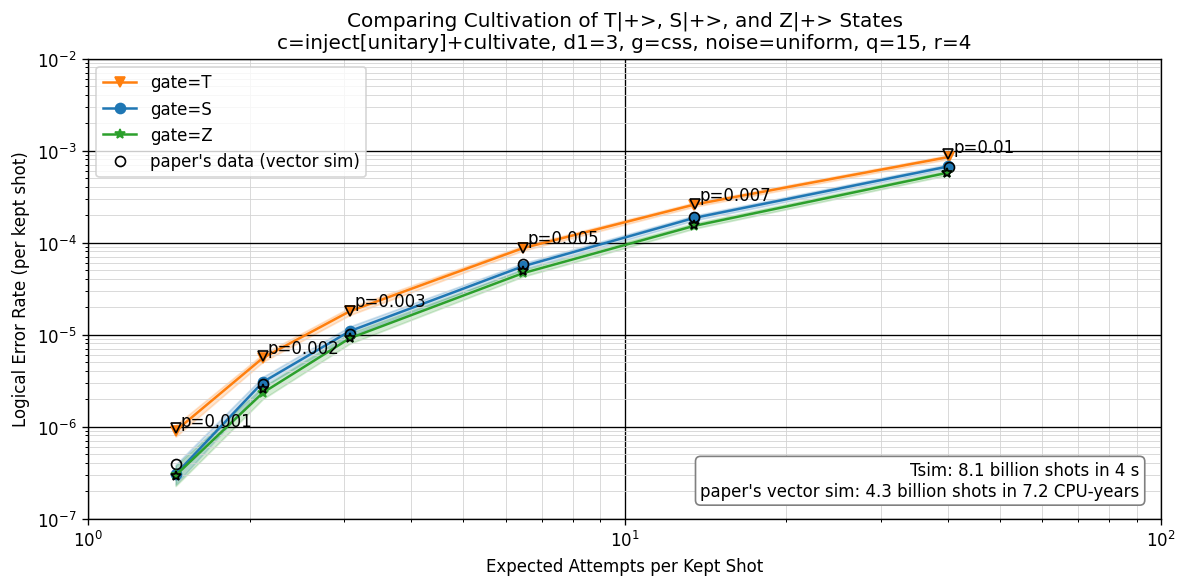

In [2]:
# Gidney, Shutty & Jones, "Magic state cultivation" (arXiv:2409.17595): cultivating T|+⟩ vs S|+⟩ vs Z|+⟩.
# The paper needed 7.2 CPU-years of state-vector simulation for this figure. Tsim uses the Stim API.
import time

import numpy as np
import tsim

from cultivation import BATCH, batches, circuit_path, plot, points

start = time.perf_counter()
tally = points()  # gates T, S, Z at six noise strengths
for point in tally:
    circuit = tsim.Circuit.from_file(circuit_path(point))
    sampler = circuit.compile_detector_sampler()
    mask = np.ones(circuit.num_detectors, dtype=bool)  # postselect: keep shots where no detector fires
    for _ in batches(point):
        detectors, observables = sampler.sample(
            BATCH, postselection_mask=mask, separate_observables=True, bit_packed=True
        )
        point.shots += BATCH
        point.kept += len(observables)
        point.errors += np.count_nonzero(observables)  # logical error: the observable flipped

plot(tally, seconds=time.perf_counter() - start)


In [3]:
@squin.kernel
def main():
    q = squin.qalloc(3)
    squin.broadcast.reset(q)
    squin.h(q[0])
    squin.t(q[0])
    squin.h(q[0])
    squin.cx(q[0], q[2])
    for i in [0, 2]:
        squin.depolarize(0.5, q[i])
        squin.cx(q[i], q[1])
    squin.measure(q[1])
    squin.cx(q[1], q[0])
    squin.broadcast.measure([q[0], q[2]])

In [4]:
c = bloqade.tsim.Circuit(main)
c.diagram(height=150)

In [5]:
c.diagram("zx")

'<div id="zxp-fa0f4e4d88fd42449c543d0b62e3ca57" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [6]:
sampler = c.compile_sampler()

In [7]:
samples = sampler.sample(shots=1_000_000)
samples

array([[False, False, False],
       [False, False, False],
       [False, False, False],
       ...,
       [ True, False, False],
       [False,  True,  True],
       [ True,  True,  True]], shape=(1000000, 3))

Tsim implements the approach described in

**Fast Classical Simulation of Quantum Circuits via Parametric Rewriting in the ZX-Calculus**

Matthew Sutcliffe and Aleks Kissinger (2024)

https://arxiv.org/abs/2403.06777

Circuits are represented as parameterized ZX diagrams, which are compiled into a contiguous datastructure for efficient sampling.

In [8]:
c.diagram("zx", scale=35);

Here, TSIM makes use of ZX diagrams in _doubled_ notation:


<img src="../figures/doubling.png" alt="doubled notation" width=650px>

In [9]:
tsim.Circuit("CNOT 0 1").diagram("zx")

'<div id="zxp-2a45d833da3842e89e0822d721243be9" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [10]:
tsim.Circuit("M 0").diagram("zx")

'<div id="zxp-324a921bd11545e89c6ffa993196beef" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [11]:
tsim.Circuit("""
    X 0
    R 0
""").diagram("zx")

'<div id="zxp-fe317694545443539b6ef05fb3af6af5" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [12]:
tsim.Circuit("""
M !0
CNOT rec[-1] 1
""").diagram("zx")

'<div id="zxp-7438882a105c4c4b9d26cc725a33f7f9" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

Pauli Channels are represented as parameterized Pauli vertices:

In [13]:
tsim.Circuit("""
    Z_ERROR(0.01) 0
""").diagram("zx")

'<div id="zxp-464e14fe87ab4dd4a3de3f3eec617f52" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [14]:
tsim.Circuit("""DEPOLARIZE2(0.01) 0 1""").diagram("zx")

'<div id="zxp-65f3d327bcb64391b9bd22208b1a69d4" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

For QEC experiments, we are often not interested in measurements themselves, but certain XOR combinations of them, referred to as _detectors_. We can directly represent detectors in ZX diagrams by applying classical XORs to measurement bits. The XOR has a simple ZX representation:

<img src="../figures/xor.png" alt="XOR gate" width=350px>

In [15]:
c = tsim.Circuit("""
    R 0 1
    H 0
    CNOT 0 1
    M 0 1
    DETECTOR rec[-1] rec[-2]
    OBSERVABLE_INCLUDE(0) rec[-1]
""")
c.diagram("zx")

'<div id="zxp-e07564f84f93497a970cedcdafbe6a91" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [16]:
sampler = c.compile_sampler()
sampler.sample(10)

array([[False, False],
       [ True,  True],
       [ True,  True],
       [ True,  True],
       [ True,  True],
       [False, False],
       [ True,  True],
       [ True,  True],
       [ True,  True],
       [ True,  True]])

In [17]:
detector_sampler = c.compile_detector_sampler()
detectors = detector_sampler.sample(10)

In [18]:
mask = detectors == 0

In [19]:
c = tsim.Circuit("""
    RX 0
    R 1 2 3 4 5
    T 0
    H 0
    CNOT 0 2
    CNOT 0 3
    CNOT 2 5
    TICK
    CX 0 1 3 4
    X_ERROR(0.01) 0 1 3 4
    TICK
    CX 2 1 5 4
    X_ERROR(0.01) 2 1 5 4
    TICK
    MR 1 4
    DETECTOR rec[-2]
    DETECTOR rec[-1]
    TICK
    CX 0 1 3 4
    X_ERROR(0.01) 0 1 3 4
    TICK
    CX 2 1 5 4
    X_ERROR(0.01) 2 1 5 4
    TICK
    MR 1 4
    DETECTOR rec[-2] rec[-4]
    DETECTOR rec[-1] rec[-3]
    M 0 2 3 5
    DETECTOR rec[-3] rec[-4] rec[-6]
    DETECTOR rec[-1] rec[-2] rec[-5]
    OBSERVABLE_INCLUDE(0) rec[-3]
    OBSERVABLE_INCLUDE(1) rec[-1]
""")

In [20]:
c.diagram(height=200)

In [21]:
c.diagram("zx", scale=30, scale_horizontally=1.4);

In [22]:
c.diagram("zx-dets", scale_horizontally=2);

# Clifford sampling

In [23]:
p = 1e-4
stim_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    rounds=7,
    distance=7,
    before_round_data_depolarization=p,
    before_measure_flip_probability=p,
    after_clifford_depolarization=p,
    after_reset_flip_probability=p,
)
stim_sampler = stim_circuit.compile_detector_sampler()

circuit = tsim.Circuit.from_stim_program(stim_circuit)
sampler = circuit.compile_detector_sampler()

In [24]:
circuit.without_noise().diagram("timeslice-svg", height=250, rows=1)

In [25]:
# circuit.diagram("zx", scale_horizontally=2)

In [26]:
# Heavy benchmark, commented out. Uncomment to run.
# num_samples = 1024**2 * 64
#
# start = time.perf_counter()
# samples = sampler.sample(shots=num_samples)
# end = time.perf_counter()
# print(f"Time per shot (tsim): {(end - start) * 1e9 / num_samples:.1f} ns")

In [27]:
# Heavy benchmark, commented out. Uncomment to run.
# num_samples = 1024
# repeats = 1024 * 8
#
# start = time.perf_counter()
# for _ in range(repeats):
#     samples = stim_sampler.sample(shots=num_samples)
# end = time.perf_counter()
# print(f"Time per shot (stim): {(end - start) * 1e9 / num_samples / repeats:.1f} ns")

In [28]:
# Heavy benchmark, commented out. Uncomment to run.
# import sinter
# import matplotlib.pyplot as plt
#
# noise_vals = np.logspace(-3, -2, 4)
# tasks = [
#     sinter.Task(
#         circuit=tsim.Circuit.from_stim_program(
#             stim.Circuit.generated(
#                 "surface_code:rotated_memory_z",
#                 distance=distance,
#                 rounds=distance,
#                 after_clifford_depolarization=noise,
#                 before_round_data_depolarization=noise,
#                 before_measure_flip_probability=noise,
#                 after_reset_flip_probability=noise,
#             )
#         ),
#         json_metadata={"p": noise, "distance": distance, "rounds": 3},
#     )
#     for noise in noise_vals
#     for distance in [3, 5, 7]
# ]
#
# collected_stats = sinter.collect(
#     num_workers=8,
#     tasks=tasks,
#     decoders=["pymatching"],
#     max_shots=1024 * 256,
#     start_batch_size=1024 * 256,
#     max_batch_size=1024 * 256,
# )
#
# fig, ax = plt.subplots(1, 1)
# sinter.plot_error_rate(
#     ax=ax,
#     stats=collected_stats,
#     x_func=lambda stats: stats.json_metadata["p"],
#     group_func=lambda stats: stats.json_metadata["distance"],
#     failure_units_per_shot_func=lambda stats: stats.json_metadata["rounds"],
# )
# plt.plot(noise_vals, noise_vals, color="k", linestyle="--", lw=0.5, label="uncoded")
# ax.loglog()
# ax.set_xlabel("Physical Error Rate")
# ax.set_ylabel("Logical Error Rate")
# ax.legend();

## Non-Clifford circuits

In [29]:
c = tsim.Circuit.from_file("../circuits/msd_5.stim")
c.diagram(height=500)

In [30]:
c.diagram("zx-meas")

'<div id="zxp-3df8d07c90b5487ebcb72f2fb194330a" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [31]:
sampler = c.compile_detector_sampler()

In [32]:
num_samples = 50_000

start = time.perf_counter()
samples = sampler.sample(shots=num_samples)
end = time.perf_counter()
print(f"Time per shot (tsim): {(end - start) * 1e6 / num_samples:.2f} us")

Time per shot (tsim): 0.08 us


On GPU, time per shot is about $0.6 \mu s$.

In [33]:
sampler = c._stim_circ.compile_detector_sampler()

start = time.perf_counter()
num_samples = 1024
repeats = 1024
for i in range(repeats):
    samples = sampler.sample(shots=num_samples)
end = time.perf_counter()
print(f"Time per shot (stim): {(end - start) * 1e6 / num_samples / repeats:.2f} us")

Time per shot (stim): 0.53 us


In [34]:
c = tsim.Circuit.from_file("../circuits/msc_3.stim")
print(c.tcount())
c.diagram("timeslice-svg", height=200, rows=1)

16


In [35]:
c.diagram("zx-dets")

'<div id="zxp-b88672f09f9644e19c266111cdc087c9" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [36]:
sampler = c.compile_detector_sampler()

In [37]:
sampler.sample(100)  # 6ms per shot

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False,  True],
       [False, False, False, ..., False, False, False],
       [False, False, False, ...,  True, False, False]], shape=(100, 32))

On GPU, Tsim achieves $100 \mu s$ per shot. However, the performance for this circuit has been improved by to $1\mu s$ on CPU using Tsim in **Simulating magic state cultivation with few Clifford terms**, Kwok Ho Wan & Zhenghao Zhong (2026) https://arxiv.org/pdf/2509.08658.